# Fashion Image Classification with Neural Networks
# تصنيف صور الملابس باستخدام الشبكات العصبية
**Khalid Abdu Hazazi | خالد عبده هزازي**

Build a Feedforward network, a CNN, and a CNN with Dropout. Compare learning curves and classification results on Fashion-MNIST.

نبني شبكة Feedforward، ثم CNN، ثم نفس CNN مع Dropout. نقارن منحنيات التعلم والنتائج ونشوف أمثلة صحيحة وخاطئة. المشروع يستخدم مفاهيم لابات 3 و4 و5 و6، ولا يطبق كل تمارينها حرفياً.

**Run:** Open this notebook in Google Colab and run the cells from top to bottom. The dataset downloads automatically; no CSV or Google Drive mount is required. A GPU is helpful for training the three networks.

**التشغيل:** افتح الملف في Colab وشغّل الخلايا بالترتيب. البيانات تتحمّل تلقائياً، وتحتاج إنترنت أول مرة. يفضّل اختيار GPU من إعدادات بيئة التشغيل. الملف لا يحتوي نتائج تدريب محفوظة؛ تظهر النتائج الحقيقية عند تشغيله.

Educational portfolio project prepared with AI assistance. Study the code and try changing an experiment before discussing it in an interview.

## 1. Import libraries | استيراد المكتبات
Use TensorFlow/Keras for the networks, NumPy for arrays, and Matplotlib for plots.
نستخدم نفس أدوات اللابات. `SEED` يساعد على تكرار التجربة؛ النتائج قد تختلف قليلاً حسب الجهاز وإصدارات المكتبات.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import fashion_mnist
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

SEED = 42
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
GPU devices: []


## 2. Load the dataset | تحميل البيانات
Fashion-MNIST contains 60,000 training images and 10,000 test images, each 28×28 pixels in grayscale. There are ten clothing categories.
الصور جاهزة ومعها الإجابات الصحيحة. الصورة رمادية لذلك لها قناة واحدة. نحتفظ بمجموعة الاختبار للتقييم الأخير.

Dataset: [Keras Fashion-MNIST documentation](https://keras.io/api/datasets/fashion_mnist/). Original dataset: [Zalando Research](https://github.com/zalandoresearch/fashion-mnist).

In [2]:
(all_train_images, all_train_labels), (test_images, test_labels) = fashion_mnist.load_data()

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Original training images:", all_train_images.shape)
print("Test images:", test_images.shape)
print("Pixel range:", all_train_images.min(), "to", all_train_images.max())
print("Number of classes:", len(class_names))


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Original training images: (60000, 28, 28)
Test images: (10000, 28, 28)
Pixel range: 0 to 255
Number of classes: 10


## 3. Explore the images | استكشاف الصور
Show example images and their actual labels, and count images in each training category.
نشوف شكل البيانات وعدد الصور في كل فئة قبل تدريب النماذج.

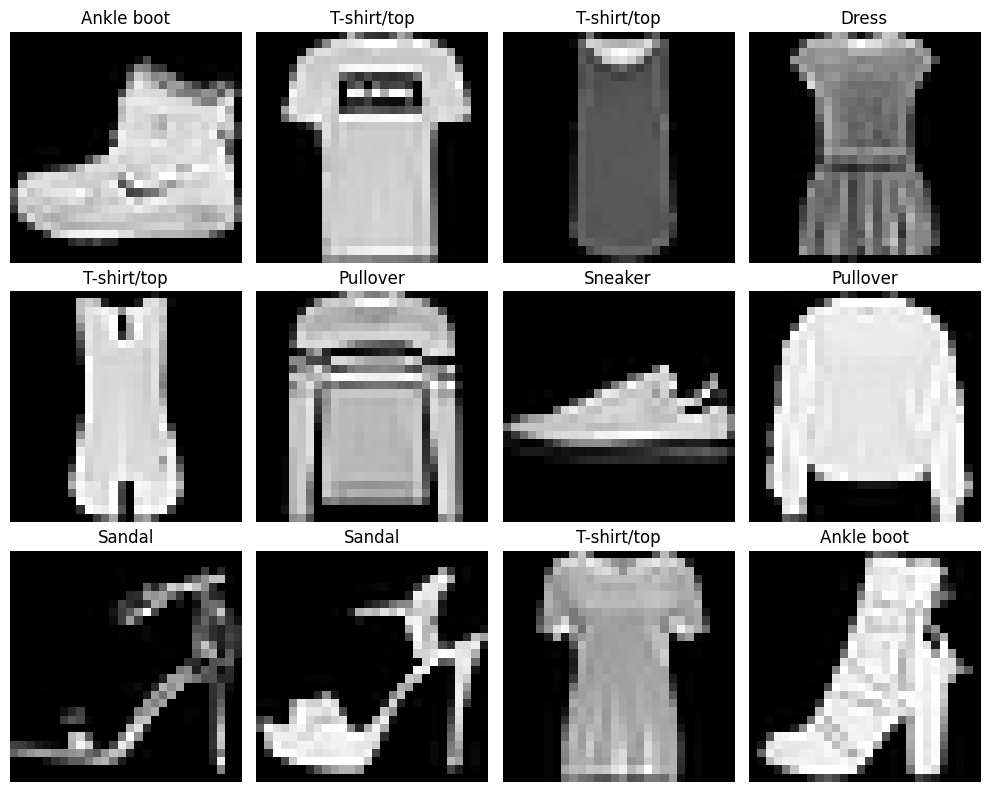

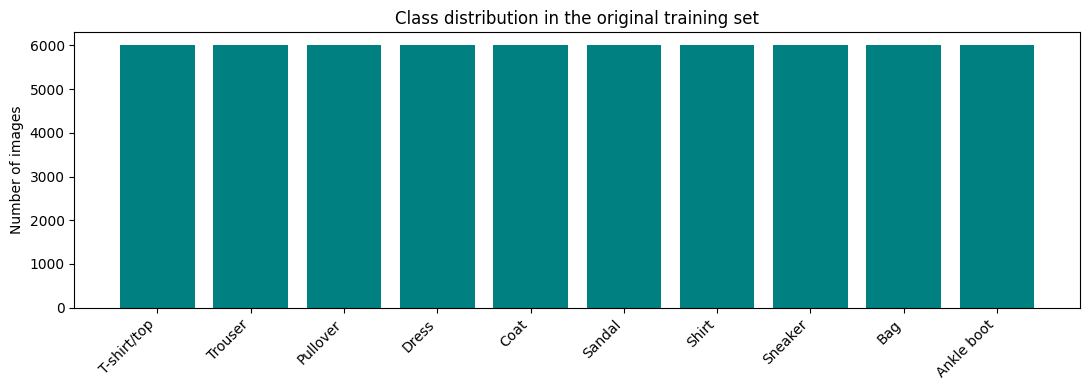

In [3]:
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for index, ax in enumerate(axes.flat):
    ax.imshow(all_train_images[index], cmap="gray")
    ax.set_title(class_names[all_train_labels[index]])
    ax.axis("off")
plt.tight_layout()
plt.show()

counts = np.bincount(all_train_labels, minlength=10)
plt.figure(figsize=(11, 4))
plt.bar(class_names, counts, color="teal")
plt.title("Class distribution in the original training set")
plt.ylabel("Number of images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 4. Choose a subset and split | اختيار جزء من البيانات وتقسيمه
Use a reproducible, stratified sample of 30,000 images to reduce training time. Split it into 24,000 training images and 6,000 validation images. All models use the exact same split. The official test set stays separate.

نختار 30 ألف صورة مع الحفاظ على نسب الفئات، ثم 80% تدريب و20% تحقق. التدريب لتعلّم الأوزان، والتحقق للمقارنة واختيار النموذج، والاختبار للتقييم الأخير. لا نستخدم الاختبار لاختيار الإعدادات.

In [4]:
TRAINING_SAMPLE = 30000
EPOCHS = 10
BATCH_SIZE = 64
LEARNING_RATE = 0.001

subset_images, _, subset_labels, _ = train_test_split(
    all_train_images, all_train_labels,
    train_size=TRAINING_SAMPLE, stratify=all_train_labels, random_state=SEED
)

train_images, val_images, train_labels, val_labels = train_test_split(
    subset_images, subset_labels,
    test_size=0.2, stratify=subset_labels, random_state=SEED
)

print("Train:", train_images.shape)
print("Validation:", val_images.shape)
print("Test:", test_images.shape)


Train: (24000, 28, 28)
Validation: (6000, 28, 28)
Test: (10000, 28, 28)


## 5. Prepare the data | تجهيز البيانات
Divide pixels by 255, add one channel, and one-hot encode labels exactly as in the CNN lab.
نقسم البكسلات على 255 لتصبح بين 0 و1. الشكل الجديد للصورة `(28, 28, 1)`. الإجابة تصبح متجهاً من عشرة أرقام، فيه 1 في موضع الفئة الصحيحة.

In [5]:
x_train = train_images.astype("float32")[..., np.newaxis] / 255.0
x_val = val_images.astype("float32")[..., np.newaxis] / 255.0
x_test = test_images.astype("float32")[..., np.newaxis] / 255.0

y_train = tf.keras.utils.to_categorical(train_labels, num_classes=10)
y_val = tf.keras.utils.to_categorical(val_labels, num_classes=10)
y_test = tf.keras.utils.to_categorical(test_labels, num_classes=10)

print("Input shape:", x_train.shape)
print("Output shape:", y_train.shape)
print("First actual class:", class_names[train_labels[0]])
print("First one-hot label:", y_train[0])


Input shape: (24000, 28, 28, 1)
Output shape: (24000, 10)
First actual class: Shirt
First one-hot label: [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


## 6. Build a Feedforward network | بناء شبكة Feedforward
Flatten turns each image into 784 input values. Two Dense layers learn patterns; ten Softmax outputs correspond to the ten classes.
نحوّل الصورة إلى قائمة، ثم نستخدم Dense مع ReLU وطبقة إخراج Softmax. هذا تطبيق لفكرة شبكات Feedforward التي أخذتوها.

In [6]:
def build_feedforward():
    return models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])

feedforward = build_feedforward()
feedforward.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Build the CNN models | بناء CNN والمقارنة مع Dropout
Conv2D extracts spatial patterns; MaxPooling2D reduces their size; Flatten and Dense produce the final class prediction.

نستخدم طبقات CNN بنفس فكرة لاب 6. مع `valid` يصبح الشكل: 26×26×32 ثم 13×13×32 ثم 11×11×64 ثم 5×5×64. Flatten يعطي 1600 قيمة.

The second CNN uses the same architecture plus Dropout(0.5). It randomly sets half the Dense activations to zero during training; Keras disables Dropout during evaluation and prediction.
النسخة الثانية تضيف Dropout لتجربة تقليل فرط التعلّم؛ التحسن غير مضمون ونحكم عليه من النتائج.

In [7]:
def build_cnn(dropout_rate=0.0):
    model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (3, 3), activation="relu", padding="valid"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu", padding="valid"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation="relu")
    ])
    if dropout_rate > 0:
        model.add(layers.Dropout(dropout_rate))
    model.add(layers.Dense(10, activation="softmax"))
    return model

cnn = build_cnn()
cnn_dropout = build_cnn(dropout_rate=0.5)
cnn.summary()
cnn_dropout.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Compile and train | تجهيز التدريب وتدريب النماذج
All models use Adam, the same learning rate, batch size and epoch count. Categorical cross-entropy matches the one-hot labels and Softmax output.
ندرب النماذج الثلاثة بنفس تقسيم البيانات والإعدادات. `fit` يعلّم النموذج، وبيانات التحقق تراقب أداءه بدون تحديث الأوزان منها. هذا مقارنة تعليمية بإعدادات ثابتة، وليس بحثاً شاملاً عن أفضل إعدادات.

In [8]:
model_dict = {
    "Feedforward": feedforward,
    "CNN": cnn,
    "CNN + Dropout": cnn_dropout
}
histories = {}

for name, model in model_dict.items():
    print("\nTraining:", name)
    tf.keras.utils.set_random_seed(SEED)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    histories[name] = model.fit(
        x_train, y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_data=(x_val, y_val),
        verbose=2
    )



Training: Feedforward
Epoch 1/10
375/375 - 11s - 28ms/step - accuracy: 0.7819 - loss: 0.6223 - val_accuracy: 0.8100 - val_loss: 0.5465
Epoch 2/10
375/375 - 3s - 9ms/step - accuracy: 0.8445 - loss: 0.4370 - val_accuracy: 0.8340 - val_loss: 0.4679
Epoch 3/10
375/375 - 2s - 5ms/step - accuracy: 0.8616 - loss: 0.3844 - val_accuracy: 0.8463 - val_loss: 0.4287
Epoch 4/10
375/375 - 3s - 7ms/step - accuracy: 0.8740 - loss: 0.3490 - val_accuracy: 0.8567 - val_loss: 0.4000
Epoch 5/10
375/375 - 4s - 12ms/step - accuracy: 0.8806 - loss: 0.3246 - val_accuracy: 0.8598 - val_loss: 0.3909
Epoch 6/10
375/375 - 2s - 5ms/step - accuracy: 0.8879 - loss: 0.3039 - val_accuracy: 0.8630 - val_loss: 0.3786
Epoch 7/10
375/375 - 2s - 5ms/step - accuracy: 0.8952 - loss: 0.2877 - val_accuracy: 0.8622 - val_loss: 0.3762
Epoch 8/10
375/375 - 2s - 5ms/step - accuracy: 0.8995 - loss: 0.2733 - val_accuracy: 0.8670 - val_loss: 0.3751
Epoch 9/10
375/375 - 3s - 9ms/step - accuracy: 0.9041 - loss: 0.2601 - val_accuracy: 0

## 9. Plot learning curves | رسم منحنيات التعلم
Compare training and validation accuracy/loss for every model.
إذا استمر انخفاض Training loss بينما بدأ Validation loss يرتفع، فهذه علامة محتملة على فرط التعلّم. لا نحكم من دقة التدريب وحدها.

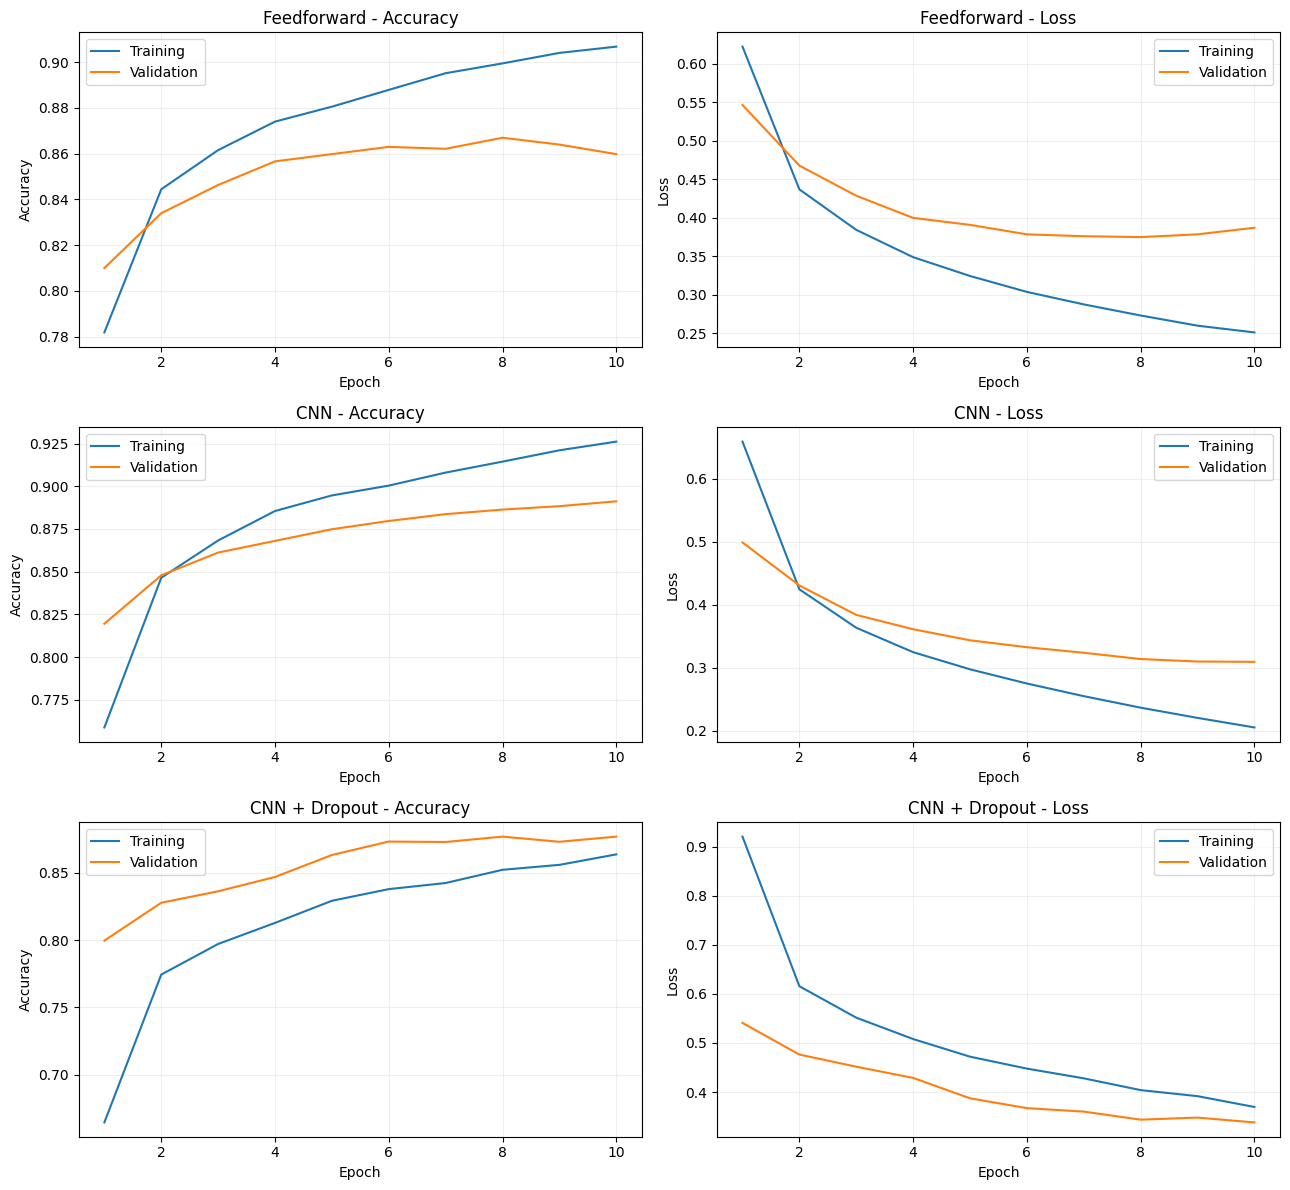

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(13, 12))
for row, (name, history) in enumerate(histories.items()):
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)
    axes[row, 0].plot(epochs, h["accuracy"], label="Training")
    axes[row, 0].plot(epochs, h["val_accuracy"], label="Validation")
    axes[row, 0].set_title(name + " - Accuracy")
    axes[row, 0].set_ylabel("Accuracy")
    axes[row, 1].plot(epochs, h["loss"], label="Training")
    axes[row, 1].plot(epochs, h["val_loss"], label="Validation")
    axes[row, 1].set_title(name + " - Loss")
    axes[row, 1].set_ylabel("Loss")
    for ax in axes[row]:
        ax.set_xlabel("Epoch")
        ax.legend()
        ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 10. Compare validation results | مقارنة نتائج التحقق
Choose the model using final-epoch validation accuracy, with validation loss as the tie-breaker, before inspecting test results. Models retain their final-epoch weights.
نختار النموذج حسب نتائج التحقق عند نهاية التدريب، لا حسب الاختبار. نعرض أيضاً الفرق بين دقة التدريب والتحقق، لكن هذا الفرق وحده لا يكفي للحكم على فرط التعلّم.

In [10]:
validation_rows = []
for name, history in histories.items():
    h = history.history
    validation_rows.append({
        "Model": name,
        "Train accuracy": h["accuracy"][-1],
        "Validation accuracy": h["val_accuracy"][-1],
        "Validation loss": h["val_loss"][-1],
        "Accuracy gap": h["accuracy"][-1] - h["val_accuracy"][-1]
    })

validation_table = pd.DataFrame(validation_rows).sort_values(
    ["Validation accuracy", "Validation loss"], ascending=[False, True]
).reset_index(drop=True)
print(validation_table.round(4).to_string(index=False))

best_name = validation_table.loc[0, "Model"]
best_model = model_dict[best_name]
print("\nSelected using validation data:", best_name)


        Model  Train accuracy  Validation accuracy  Validation loss  Accuracy gap
          CNN          0.9261               0.8912           0.3095        0.0350
CNN + Dropout          0.8638               0.8770           0.3380       -0.0132
  Feedforward          0.9068               0.8598           0.3872        0.0470

Selected using validation data: CNN


## 11. Final test evaluation | التقييم الأخير على الاختبار
Report Accuracy, macro F1 and loss for all three fixed models. The selected model stays the one chosen with validation data; do not change it after seeing test results.
Accuracy هي نسبة التوقعات الصحيحة. Macro F1 يحسب F1 لكل فئة ثم يأخذ متوسطها بالتساوي. نتائج الاختبار لا نرجع نستخدمها لضبط الإعدادات.

In [11]:
test_rows = []
test_predictions = {}
for name, model in model_dict.items():
    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
    probabilities = model.predict(x_test, batch_size=256, verbose=0)
    predicted_labels = np.argmax(probabilities, axis=1)
    test_predictions[name] = predicted_labels
    test_rows.append({
        "Model": name,
        "Test accuracy": accuracy,
        "Macro F1": f1_score(test_labels, predicted_labels, average="macro", zero_division=0),
        "Test loss": loss
    })

test_table = pd.DataFrame(test_rows)
print(test_table.round(4).to_string(index=False))
print("\nValidation-selected model:", best_name)

best_predictions = test_predictions[best_name]
print("\nClassification report:")
print(classification_report(
    test_labels, best_predictions,
    labels=np.arange(10), target_names=class_names, zero_division=0
))


        Model  Test accuracy  Macro F1  Test loss
  Feedforward         0.8581    0.8584     0.4067
          CNN         0.8925    0.8934     0.3080
CNN + Dropout         0.8760    0.8757     0.3432

Validation-selected model: CNN

Classification report:
              precision    recall  f1-score   support

 T-shirt/top       0.87      0.82      0.84      1000
     Trouser       0.99      0.98      0.98      1000
    Pullover       0.84      0.83      0.84      1000
       Dress       0.89      0.92      0.90      1000
        Coat       0.87      0.78      0.82      1000
      Sandal       0.98      0.96      0.97      1000
       Shirt       0.66      0.75      0.70      1000
     Sneaker       0.95      0.95      0.95      1000
         Bag       0.97      0.97      0.97      1000
  Ankle boot       0.94      0.97      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.90      0.89      0.89     10000
weighted avg       0.90      0.89      0

## 12. Confusion matrix | مصفوفة الالتباس
Rows are actual categories; columns are predicted categories. Off-diagonal counts show mistakes.
القطر الرئيسي للتوقعات الصحيحة، والخلايا الأخرى توضح أي أنواع الملابس اختلطت على النموذج.

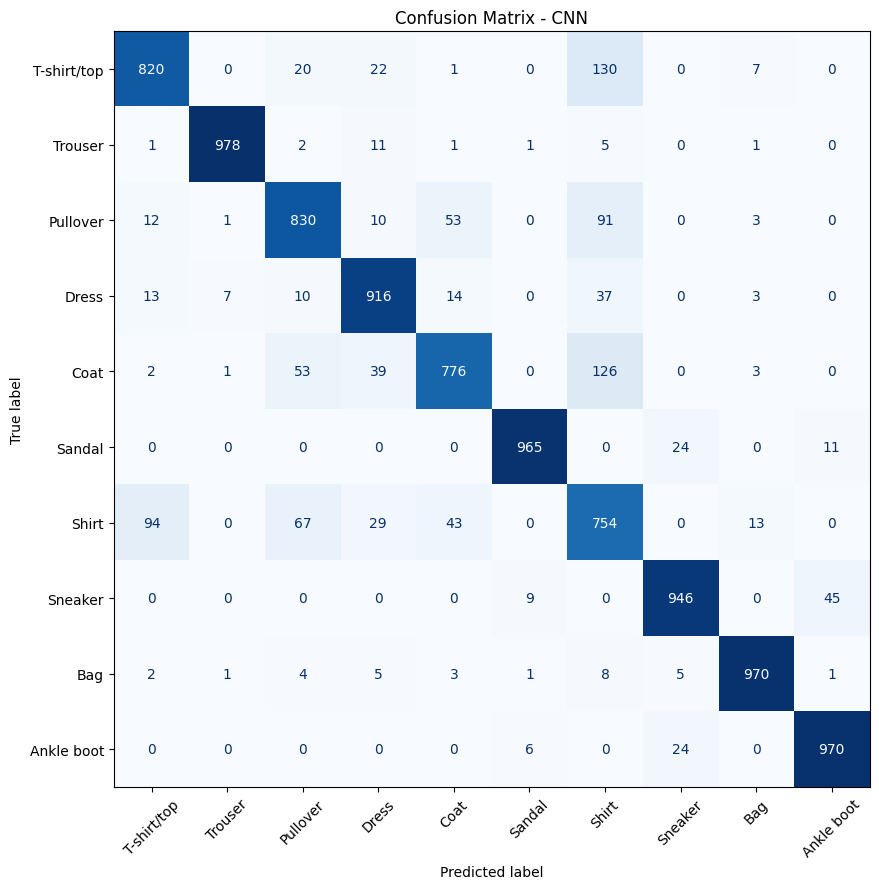

In [12]:
fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay.from_predictions(
    test_labels, best_predictions,
    labels=np.arange(10), display_labels=class_names,
    cmap="Blues", xticks_rotation=45, ax=ax, colorbar=False
)
ax.set_title("Confusion Matrix - " + best_name)
plt.tight_layout()
plt.show()


## 13. Display predictions and errors | عرض التوقعات والأخطاء
Compare predicted and actual labels. Green means correct; red means incorrect. Then inspect up to eight errors.
نراجع صوراً من الاختبار ونشوف التوقع الصحيح والخاطئ. الأمثلة هنا صور من نفس مجموعة Fashion-MNIST؛ لم نضف رفع صور جوال أو تصوير ملابس حقيقية.

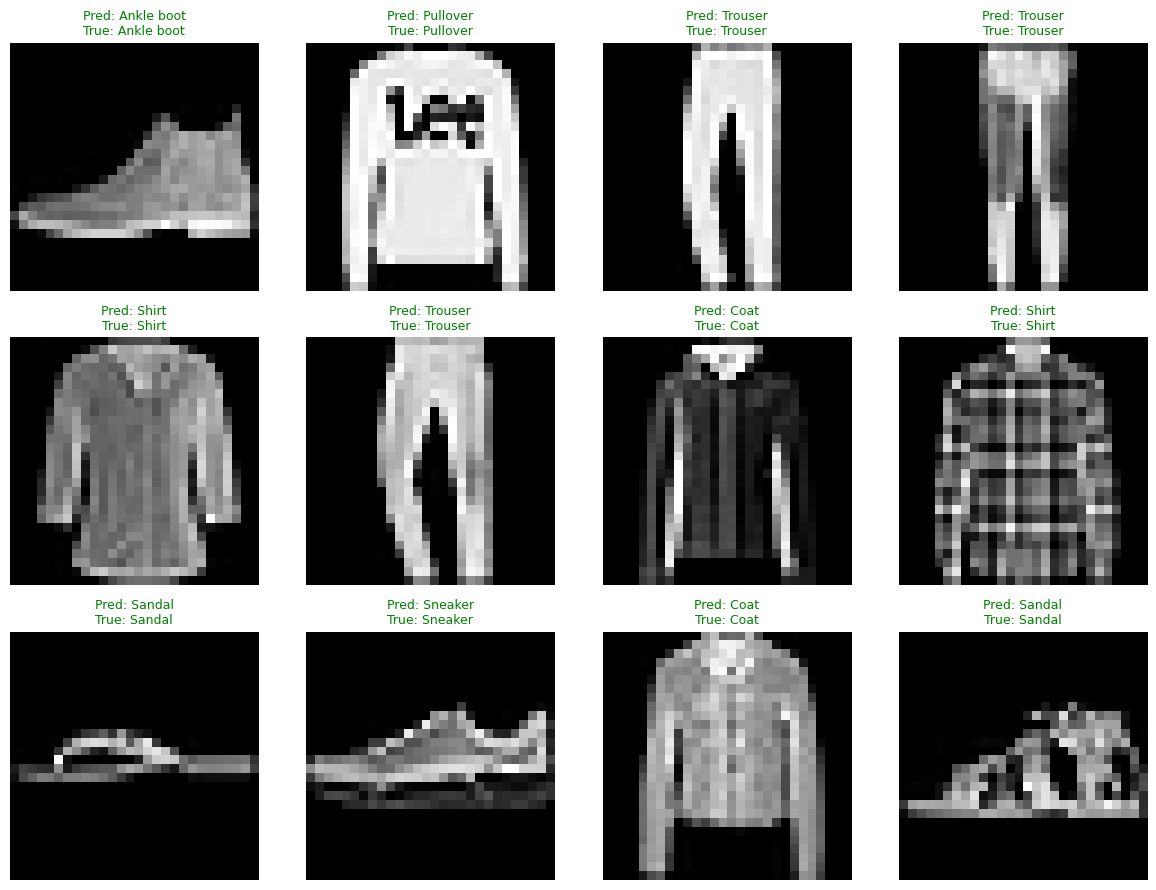

Total incorrect predictions: 1075


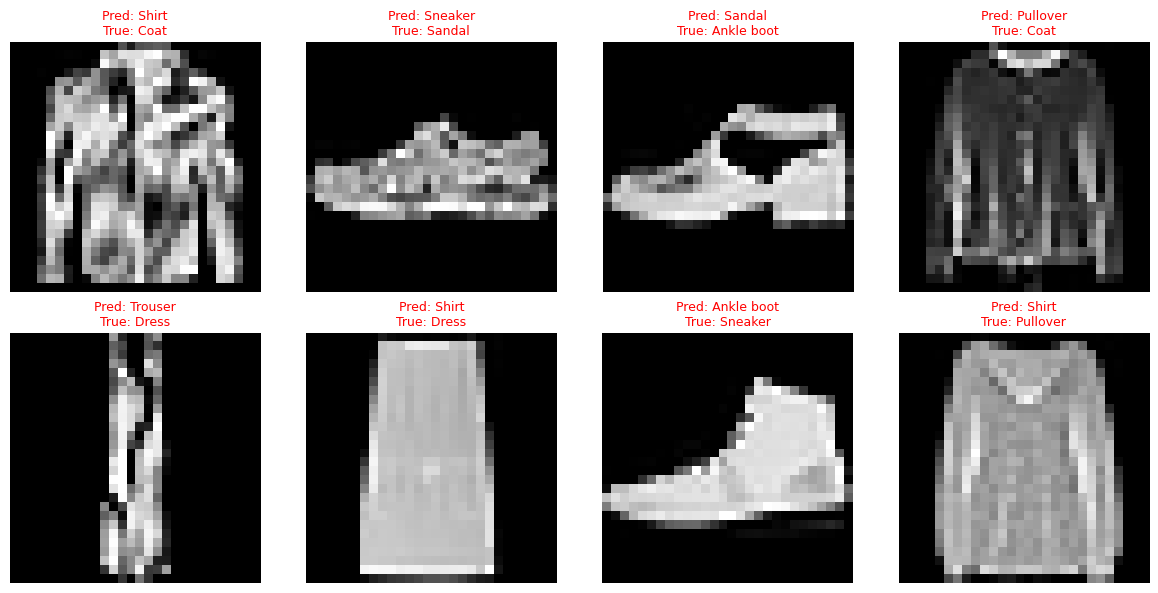

In [13]:
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for index, ax in enumerate(axes.flat):
    actual = test_labels[index]
    predicted = best_predictions[index]
    ax.imshow(x_test[index, :, :, 0], cmap="gray")
    ax.set_title(
        f"Pred: {class_names[predicted]}\nTrue: {class_names[actual]}",
        color="green" if predicted == actual else "red", fontsize=9
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

wrong_indices = np.flatnonzero(best_predictions != test_labels)
print("Total incorrect predictions:", len(wrong_indices))
if len(wrong_indices) > 0:
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for ax in axes.flat:
        ax.axis("off")
    for index, ax in zip(wrong_indices[:8], axes.flat):
        ax.imshow(x_test[index, :, :, 0], cmap="gray")
        ax.set_title(
            f"Pred: {class_names[best_predictions[index]]}\nTrue: {class_names[test_labels[index]]}",
            color="red", fontsize=9
        )
    plt.tight_layout()
    plt.show()


## 14. Try one image | جرّب صورة واحدة
Change `image_index` to an integer from 0 to 9999 and run this cell again.
غيّر رقم الصورة ثم شغّل هذه الخلية فقط بعد إكمال التدريب. لا تحتاج إعادة تدريب النماذج لتجربة صورة أخرى.

Model: CNN
Prediction: Pullover
Actual: Coat
Largest softmax score: 0.6523


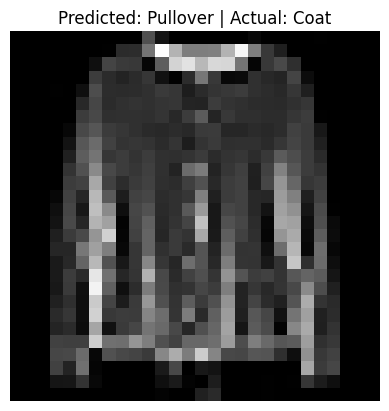

In [14]:
image_index = 25
if not 0 <= image_index < len(x_test):
    raise ValueError(f"Choose an image_index between 0 and {len(x_test) - 1}")

prediction = best_model.predict(x_test[image_index:image_index + 1], verbose=0)[0]
predicted_class = int(np.argmax(prediction))
actual_class = int(test_labels[image_index])
print("Model:", best_name)
print("Prediction:", class_names[predicted_class])
print("Actual:", class_names[actual_class])
print("Largest softmax score:", round(float(prediction[predicted_class]), 4))

plt.imshow(x_test[image_index, :, :, 0], cmap="gray")
plt.title(f"Predicted: {class_names[predicted_class]} | Actual: {class_names[actual_class]}")
plt.axis("off")
plt.show()


## 15. Interpret your experiment | تفسير تجربتك
Print a summary generated from actual results rather than assuming CNN or Dropout must win.
الملخص التالي يعتمد على نتائج تشغيلك الفعلية. تغيّر النتيجة بين تشغيل وآخر لا يعني أن الكود خطأ. أكبر قيمة Softmax ليست ضماناً لصحة التوقع ولا مقياساً معايراً للثقة.

In [15]:
selected_test_row = test_table.loc[test_table["Model"] == best_name].iloc[0]
print("Selected model (validation):", best_name)
print(f"Its test accuracy: {selected_test_row['Test accuracy']:.2%}")
print(f"Its macro F1: {selected_test_row['Macro F1']:.4f}")

comparison = validation_table.set_index("Model")
difference = (
    comparison.loc["CNN + Dropout", "Validation accuracy"]
    - comparison.loc["CNN", "Validation accuracy"]
)
print(f"Dropout change in validation accuracy: {difference * 100:+.2f} percentage points")
print("Inspect the loss curves before deciding whether overfitting decreased.")
print("These are results from one split and one run, not proof that one architecture always wins.")


Selected model (validation): CNN
Its test accuracy: 89.25%
Its macro F1: 0.8934
Dropout change in validation accuracy: -1.42 percentage points
Inspect the loss curves before deciding whether overfitting decreased.
These are results from one split and one run, not proof that one architecture always wins.


## 16. What did I build? | ماذا أنجزت؟
**English:** Built and compared Feedforward and Convolutional Neural Networks for clothing image classification using TensorFlow/Keras. Preprocessed Fashion-MNIST images, studied the effect of Dropout, and evaluated learning curves, accuracy, macro F1 and classification errors.

**العربي:** بنيت وقارنت شبكة Feedforward وشبكة CNN لتصنيف صور الملابس باستخدام TensorFlow وKeras. جهزت الصور ودرست تأثير Dropout، ثم قيّمت منحنيات التعلم والدقة وMacro F1 وأخطاء التصنيف.

After running, quote only the scores printed by your notebook. لا تضف نسبة دقة للسيرة قبل تشغيل المشروع والتحقق منها.

